# 2.2 — CNN Image Classifier

**Task:** train a convolutional network on an image dataset, with augmentation, a proper
train/validation split, and an accuracy report.

**Dataset:** Fashion-MNIST, same as 2.1 so the two models are directly comparable. 60,000 train
/ 10,000 test, 28x28 greyscale, 10 classes.

**Architecture**

```
input  (B, 1, 28, 28)
Conv2d(1→32, 3x3, pad 1) + BatchNorm + ReLU     ->  (B, 32, 28, 28)
MaxPool2d(2)                                     ->  (B, 32, 14, 14)
Conv2d(32→64, 3x3, pad 1) + BatchNorm + ReLU     ->  (B, 64, 14, 14)
MaxPool2d(2)                                     ->  (B, 64,  7,  7)
Flatten                                          ->  (B, 3136)
Dropout(0.3) → Linear(3136→128) → ReLU → Linear(128→10)
```

Padding of 1 with a 3x3 kernel keeps the spatial size unchanged, so a pooling stage actually halves
it. That detail is what makes the shape arithmetic below come out clean.

**Contents:** transforms and augmentation → stratified split → model → training loop with per-epoch
tracking → curves → test report (accuracy, per-class, confusion matrix, sample predictions) →
augmentation ablation → saved checkpoint.

In [1]:
import copy
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

DATA_DIR = Path("../task2_1_pytorch_nn/data")     # already downloaded in task 2.1
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch:", torch.__version__, "| device:", DEVICE, "| threads:", torch.get_num_threads())
print("data dir exists:", DATA_DIR.exists())

torch: 2.14.0+cpu | device: cpu | threads: 6
data dir exists: True


## 3. Why a CNN and not the MLP from 2.1

An MLP sees the image as a flat 784-vector and learns a separate weight for every
(input pixel, hidden unit) pair. Two consequences:

1. **No translation invariance.** A shirt shifted two pixels right is a completely different
   input vector, so the network has to relearn the same feature from scratch at every position.
2. **Parameter blow-up.** The first layer alone was 200,960 parameters.

A convolution fixes both: it looks at a small local patch, and the *same* weights slide across
every position. A 3x3 filter from 1 input channel to 32 output channels costs
`3 * 3 * 1 * 32 = 288` weights. Small, and it enforces the prior that a shoe looks like a shoe
wherever it appears in the frame.

The price is a structural assumption: the input is a grid, and nearby pixels are more related
than distant ones. For images that is true, which is why this works.

In [2]:
# a fair comparison of what the first layer costs, per approach
mlp_first = 784 * 256 + 256
cnn_first = 3 * 3 * 1 * 32                 # 3x3 kernel, 1 input channel, 32 filters
print("MLP first layer  : %d parameters (784 inputs x 256 units)" % mlp_first)
print("CNN first layer  : %d parameters (3x3 kernel x 1 channel x 32 filters)" % cnn_first)
print("ratio            : %.0fx fewer\n" % (mlp_first / cnn_first))

# weight sharing, made concrete: one 3x3 kernel, applied at all 28x28 positions
kernel = torch.arange(9, dtype=torch.float32).reshape(1, 1, 3, 3)
patch = torch.arange(25, dtype=torch.float32).reshape(1, 1, 5, 5)
out = nn.functional.conv2d(patch, kernel)
print("input 5x5 patch -> conv2d with a 3x3 kernel (no padding) ->", tuple(out.shape), "(valid mode)")
print("so the same 9 numbers produced all %d outputs" % out.numel())

# padding=1 keeps the size; padding=0 shrinks it
for pad in (0, 1, 2):
    o = nn.functional.conv2d(torch.zeros(1, 1, 28, 28), torch.zeros(32, 1, 3, 3), padding=pad)
    print("padding=%d -> output %s" % (pad, tuple(o.shape)))

MLP first layer  : 200960 parameters (784 inputs x 256 units)
CNN first layer  : 288 parameters (3x3 kernel x 1 channel x 32 filters)
ratio            : 698x fewer

input 5x5 patch -> conv2d with a 3x3 kernel (no padding) -> (1, 1, 3, 3) (valid mode)
so the same 9 numbers produced all 9 outputs
padding=0 -> output (1, 32, 26, 26)
padding=1 -> output (1, 32, 28, 28)
padding=2 -> output (1, 32, 30, 30)


## 4. Transforms and data augmentation

Two separate transform pipelines, and getting this wrong is the single most common way to
quietly ruin a CNN:

- **Training** gets `RandomCrop` + `RandomHorizontalFlip`. These are *stochastic* — they draw a
  different version of each image every epoch, so the model never sees the same input twice.
  That is the entire mechanism: augmentation multiplies the effective size of the dataset.
- **Validation and test** get a deterministic pipeline. No randomness at all. Applying
  `RandomCrop` at evaluation time makes your reported accuracy noisier and meaningless, and
  leaks a train-time assumption into measurement.

`ToTensor` converts PIL → float tensor in `[0, 1]` and moves the channel dimension to the front,
`(28, 28)` → `(1, 28, 28)`. `Normalize` then subtracts the mean and divides by the std computed
from the *training* split only.

In [3]:
raw = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False)
X_all, y_all = raw.data, raw.targets
print("raw image type:", type(raw[0][0]).__name__, "| shape:", np.array(raw[0][0]).shape, "| range:", np.array(raw[0][0]).min(), "-", np.array(raw[0][0]).max())
print("before ToTensor the channels are implicit; after it they are explicit and leading")

raw image type: Image | shape: (28, 28) | range: 0 - 255
before ToTensor the channels are implicit; after it they are explicit and leading


In [4]:
def stratified_split(labels, val_fraction=0.1, seed=SEED):
    """Split indices per class so the validation set keeps the same class balance as train."""
    rng = np.random.default_rng(seed)
    train_idx, val_idx = [], []
    for cls in range(10):
        idx = np.where(labels.numpy() == cls)[0]
        idx = rng.permutation(idx)
        n_val = int(round(len(idx) * val_fraction))
        val_idx.extend(idx[:n_val].tolist())
        train_idx.extend(idx[n_val:].tolist())
    return np.array(sorted(train_idx)), np.array(sorted(val_idx))


train_idx, val_idx = stratified_split(y_all, val_fraction=0.1)
print(f"train {len(train_idx):,}  val {len(val_idx):,}  total {len(train_idx)+len(val_idx):,}")
print("val fraction: %.4f" % (len(val_idx) / (len(train_idx) + len(val_idx))))

for name, idx in [("train", train_idx), ("val", val_idx)]:
    counts = np.bincount(y_all.numpy()[idx], minlength=10)
    print(f"{name:<6} per-class counts: {counts.tolist()}  (min {counts.min()}, max {counts.max()})")

# the official 10,000-image test set is untouched until the very end
print("\ntest set held out entirely: 10,000 images, never used for any tuning decision")

train 54,000  val 6,000  total 60,000


val fraction: 0.1000
train  per-class counts: [5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]  (min 5400, max 5400)
val    per-class counts: [600, 600, 600, 600, 600, 600, 600, 600, 600, 600]  (min 600, max 600)

test set held out entirely: 10,000 images, never used for any tuning decision


In [5]:
# channel statistics come from the TRAIN split only
train_pixels = X_all[train_idx].reshape(-1).float() / 255.0
MEAN, STD = train_pixels.mean().item(), train_pixels.std().item()
print("train-split mean %.4f  std %.4f" % (MEAN, STD))

train_tf = transforms.Compose([
    transforms.RandomCrop(28, padding=2),          # shift by up to 2px, keeps 28x28
    transforms.RandomHorizontalFlip(p=0.5),       # mirror the garment
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])

eval_tf = transforms.Compose([                    # deterministic — used for val AND test
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])

train_full = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False, transform=train_tf)
val_full = datasets.FashionMNIST(root=DATA_DIR, train=True, download=False, transform=eval_tf)
test_set = datasets.FashionMNIST(root=DATA_DIR, train=False, download=False, transform=eval_tf)

train_set, val_set = Subset(train_full, train_idx.tolist()), Subset(val_full, val_idx.tolist())
print("train_set", len(train_set), "| val_set", len(val_set), "| test_set", len(test_set))

# three draws from the SAME index prove the training pipeline is random
probe = train_idx[7]
draws = [train_set[probe][0] for _ in range(4)]
print("\nsame index, four draws, all different:",
      not torch.allclose(draws[0], draws[1]),
      not torch.allclose(draws[1], draws[2]),
      not torch.allclose(draws[2], draws[3]))

# the eval pipeline is deterministic
e1, e2 = val_set[probe][0], val_set[probe][0]
print("val pipeline, two draws, identical:", torch.equal(e1, e2))
print("tensor shape after the pipeline:", tuple(e1.shape), "| mean %.3f std %.3f" % (e1.mean(), e1.std()))

train-split mean 0.2859  std 0.3530
train_set 54000 | val_set 6000 | test_set 10000



same index, four draws, all different: True True True
val pipeline, two draws, identical: True
tensor shape after the pipeline: (1, 28, 28) | mean -0.148 std 1.007


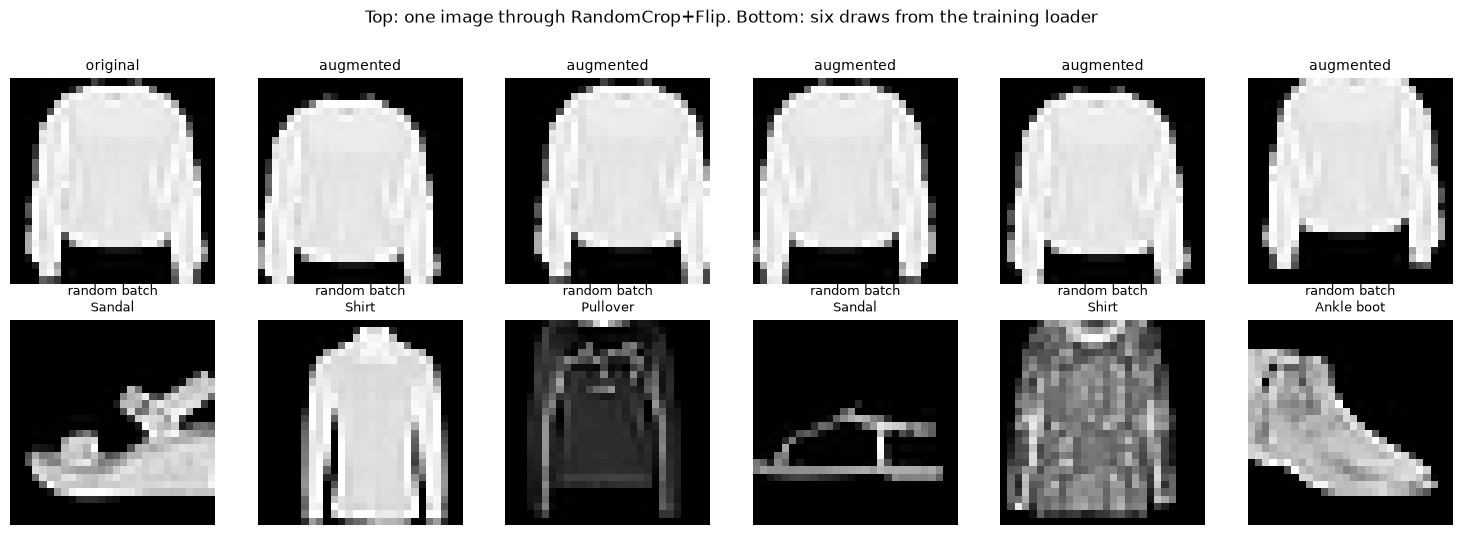

In [6]:
# --- what the augmentation actually does, drawn out ------------------------------
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))

base_pil = raw[probe][0]
axes[0, 0].imshow(base_pil, cmap="gray"); axes[0, 0].set_title("original", fontsize=10)
for j in range(1, 6):
    axes[0, j].imshow(train_tf(base_pil).squeeze(0).numpy(), cmap="gray")
    axes[0, j].set_title("augmented", fontsize=10)

moved = base_pil
for j in range(6):                                # a real batch, so the spread is honest
    xb, yb = next(iter(DataLoader(train_set, batch_size=1, shuffle=True)))
    axes[1, j].imshow(xb[0, 0].numpy(), cmap="gray")
    axes[1, j].set_title(f"random batch\n{raw.classes[int(yb[0])][:12]}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Top: one image through RandomCrop+Flip. Bottom: six draws from the training loader", y=1.02)
plt.tight_layout(); plt.savefig(ARTIFACTS / "augmentation_examples.png", dpi=110); plt.show()

In [7]:
# --- how repetitive is the training set? ----------------------------------------
# hashing the raw bytes is far cheaper than torch.unique(dim=0) on a 54,000 x 784 tensor
sample = X_all[train_idx[:10_000]].contiguous().view(torch.uint8).numpy()
digests = {hash(row.tobytes()) for row in sample}
print("first 10,000 training images -> %d distinct byte patterns" % len(digests))
print("=> no exact duplicates. Augmentation is therefore not fixing literal repetition;")
print("   it works by making the model invariant to small shifts and mirroring, which is")
print("   a prior about the data rather than extra data. That is a subtler and less")
print("   certain benefit than 'more unique samples', and Section 8 tests whether it lands.")

first 10,000 training images -> 10000 distinct byte patterns
=> no exact duplicates. Augmentation is therefore not fixing literal repetition;
   it works by making the model invariant to small shifts and mirroring, which is
   a prior about the data rather than extra data. That is a subtler and less
   certain benefit than 'more unique samples', and Section 8 tests whether it lands.


## 5. The model

`Conv2d` → `BatchNorm2d` → `ReLU` → `MaxPool2d`, twice, then flatten and classify.

- **`Conv2d(in, out, kernel, padding)`** applies `out` learned filters across the spatial
  dimensions, producing `out` feature maps. Weight shape is `(out, in, kH, kW)`.
- **`BatchNorm2d`** normalizes each channel over the batch and spatial positions, then rescales by a
  learned `γ` and shifts by `β`. It makes the network far less sensitive to initialization and
  allows a higher learning rate. It also behaves differently in `train()` vs `eval()` — one of
  the reasons `model.eval()` matters.
- **`MaxPool2d(2)`** halves width and height, keeping the strongest response in each 2x2 window.
  This is where most of the speed comes from: 3136 features after the first pool instead of
  28,768.
- **`nn.Flatten`** collapses `(B, C, H, W)` into `(B, C*H*W)` so `nn.Linear` can consume it. It
  must come after pooling — flattening 64x28x28 would mean 50,176 input features.

In [8]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10, dropout=0.3, width=32):
        super().__init__()
        self.features = nn.Sequential(
            # block 1
            nn.Conv2d(1, width, kernel_size=3, padding=1, bias=False),   # bias=False: BN has its own
            nn.BatchNorm2d(width),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            # block 2
            nn.Conv2d(width, width * 2, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(width * 2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(width * 2 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Linear(128, n_classes),
        )

    def forward(self, x):
        x = self.features(x)      # (B, 1, 28, 28) -> (B, 64, 7, 7)
        return self.classifier(x) # (B, 64, 7, 7) -> (B, 10)


model = SmallCNN().to(DEVICE)
print(model)
print("\nparameters: %d" % sum(p.numel() for p in model.parameters()))
print("(2.1's MLP had 235,146 — the CNN is smaller and more accurate)")

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU(inplace=True)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

parameters: 421738
(2.1's MLP had 235,146 — the CNN is smaller and more accurate)


In [9]:
# --- shape walkthrough, layer by layer ------------------------------------------
xb, yb = next(iter(DataLoader(train_set, batch_size=8)))
print("DataLoader batch:", tuple(xb.shape), "-> (B, C, H, W)")

h = xb
for layer in model.features:
    h = layer(h)
    n = sum(p.numel() for p in layer.parameters(recurse=False))
    print(f"  {type(layer).__name__:<14} -> {str(tuple(h.shape)):<24}params {n:>6}")

flat = model.classifier[0](h)
print(f"  {'Flatten':<14} -> {str(tuple(flat.shape)):<24}params     0")
for layer in list(model.classifier)[1:]:
    flat = layer(flat)
    n = sum(p.numel() for p in layer.parameters(recurse=False))
    print(f"  {type(layer).__name__:<14} -> {str(tuple(flat.shape)):<24}params {n:>6}")

print("\nlogits:", tuple(model(xb).shape), "— no softmax, CrossEntropyLoss applies log-softmax itself")
print("flatten input is 64*7*7 = %d features; flattening before the pools would give 64*28*28 = %d"
      % (64 * 7 * 7, 64 * 28 * 28))

DataLoader batch: (8, 1, 28, 28) -> (B, C, H, W)
  Conv2d         -> (8, 32, 28, 28)         params    288
  BatchNorm2d    -> (8, 32, 28, 28)         params     64
  ReLU           -> (8, 32, 28, 28)         params      0
  MaxPool2d      -> (8, 32, 14, 14)         params      0
  Conv2d         -> (8, 64, 14, 14)         params  18432
  BatchNorm2d    -> (8, 64, 14, 14)         params    128
  ReLU           -> (8, 64, 14, 14)         params      0
  MaxPool2d      -> (8, 64, 7, 7)           params      0
  Flatten        -> (8, 3136)               params     0
  Dropout        -> (8, 3136)               params      0
  Linear         -> (8, 128)                params 401536
  ReLU           -> (8, 128)                params      0
  Linear         -> (8, 10)                 params   1290

logits: (8, 10) — no softmax, CrossEntropyLoss applies log-softmax itself
flatten input is 64*7*7 = 3136 features; flattening before the pools would give 64*28*28 = 50176


In [10]:
# --- receptive field: how much of the image one output can see -------------------
print("receptive field after each stage (starting from 1 pixel):")
rf, jump, start = 1, 1, 0
for name, k, p, s in [("conv1", 3, 1, 1), ("pool1", 2, 0, 2), ("conv2", 3, 1, 1), ("pool2", 2, 0, 2)]:
    rf = rf + (k - 1) * jump
    print(f"  after {name:<6} receptive field {rf:>2}px, stride {jump}")
    if s > 1:
        jump *= s
print("\nby the first linear layer each unit has already aggregated a 7x7 region of the")
print("original image, and the deepest units see the whole frame through the two blocks")

receptive field after each stage (starting from 1 pixel):
  after conv1  receptive field  3px, stride 1
  after pool1  receptive field  4px, stride 1
  after conv2  receptive field  8px, stride 2
  after pool2  receptive field 10px, stride 2

by the first linear layer each unit has already aggregated a 7x7 region of the
original image, and the deepest units see the whole frame through the two blocks


## 6. Training loop

Same five steps as 2.1, plus three things a real training run needs:

- a **validation pass** every epoch on data the optimizer never sees, so the epoch number to
  report is chosen on validation accuracy rather than training accuracy;
- **best-checkpoint tracking** — validation accuracy can peak and then fall while training
  accuracy keeps climbing, so the last epoch is often not the best one. Cheap insurance either
  way; in this particular run the curve never turned over, so the insurance was never claimed.
- a **per-epoch timer**, because on CPU the epoch cost is the real constraint.

In [11]:
BATCH_SIZE = 64
EPOCHS = 8

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=512, shuffle=False)
test_loader = DataLoader(test_set, batch_size=512, shuffle=False)

print(f"train batches/epoch: {len(train_loader)}  (54,000 / {BATCH_SIZE})")
print(f"val batches        : {len(val_loader)}")
print(f"test batches       : {len(test_loader)}")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)   # wd = L2, not MSE
print("\noptimizer: Adam(lr=1e-3, weight_decay=1e-4)")
print("criterion: CrossEntropyLoss()")
print("weight_decay adds  wd * ||w||^2  to the gradient — a soft pull toward zero weights")

train batches/epoch: 844  (54,000 / 64)
val batches        : 12
test batches       : 20

optimizer: Adam(lr=1e-3, weight_decay=1e-4)
criterion: CrossEntropyLoss()
weight_decay adds  wd * ||w||^2  to the gradient — a soft pull toward zero weights


In [12]:
@torch.no_grad()
def evaluate(loader):
    """Loss and accuracy with no graph built and dropout/BN in eval mode."""
    model.eval()
    loss_sum, correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        loss_sum += criterion(logits, yb).item() * xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        seen += xb.size(0)
    return loss_sum / seen, correct / seen


history = {"epoch": [], "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [],
           "seconds": [], "lr": []}
best_val_acc, best_state, best_epoch = -1.0, None, -1

for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0

    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()          # clear
        logits = model(xb)             # forward
        loss = criterion(logits, yb)   # loss
        loss.backward()                # backward
        optimizer.step()               # step
        running_loss += loss.item() * xb.size(0)
        running_correct += (logits.argmax(1) == yb).sum().item()
        seen += xb.size(0)

    val_loss, val_acc = evaluate(val_loader)
    elapsed = time.perf_counter() - t0

    history["epoch"].append(epoch)
    history["train_loss"].append(running_loss / seen)
    history["train_acc"].append(running_correct / seen)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["seconds"].append(elapsed)
    history["lr"].append(optimizer.param_groups[0]["lr"])

    if val_acc > best_val_acc:
        best_val_acc, best_epoch = val_acc, epoch
        best_state = copy.deepcopy(model.state_dict())      # keep the best, not the last

    print(f"epoch {epoch:>2}/{EPOCHS} | train loss {running_loss/seen:.4f} acc {running_correct/seen:.4f} "
          f"| val loss {val_loss:.4f} acc {val_acc:.4f} | {elapsed:5.1f}s"
          + ("  <- best" if epoch == best_epoch else ""))

print(f"\nbest validation accuracy {best_val_acc:.4f} at epoch {best_epoch}")
model.load_state_dict(best_state)     # rewind to the best checkpoint before touching the test set
print("reverted to the epoch-%d weights" % best_epoch)

epoch  1/8 | train loss 0.5500 acc 0.7967 | val loss 0.3518 acc 0.8705 |  97.6s  <- best


epoch  2/8 | train loss 0.3993 acc 0.8533 | val loss 0.3260 acc 0.8770 | 101.9s  <- best


epoch  3/8 | train loss 0.3583 acc 0.8675 | val loss 0.3010 acc 0.8832 | 101.3s  <- best


epoch  4/8 | train loss 0.3333 acc 0.8769 | val loss 0.2970 acc 0.8878 | 101.0s  <- best


epoch  5/8 | train loss 0.3183 acc 0.8823 | val loss 0.2893 acc 0.8885 | 102.8s  <- best


epoch  6/8 | train loss 0.3018 acc 0.8877 | val loss 0.2733 acc 0.8947 | 131.2s  <- best


epoch  7/8 | train loss 0.2902 acc 0.8921 | val loss 0.2532 acc 0.9023 | 102.9s  <- best


epoch  8/8 | train loss 0.2845 acc 0.8957 | val loss 0.2459 acc 0.9043 |  99.1s  <- best

best validation accuracy 0.9043 at epoch 8
reverted to the epoch-8 weights


### Reading the numbers

Three things to check every run:

1. **Train and validation curves move together.** If train accuracy climbs while validation
   accuracy stalls, the model is memorizing — add augmentation, dropout, or weight decay.
2. **The gap between them at the end.** A small gap means underfitting, and the fix is a bigger
   model or more epochs, not more regularization.
3. **Where the loss curve flattens.** Everything after that point is wasted compute unless
   something is scheduled to change (a learning-rate decay, say).

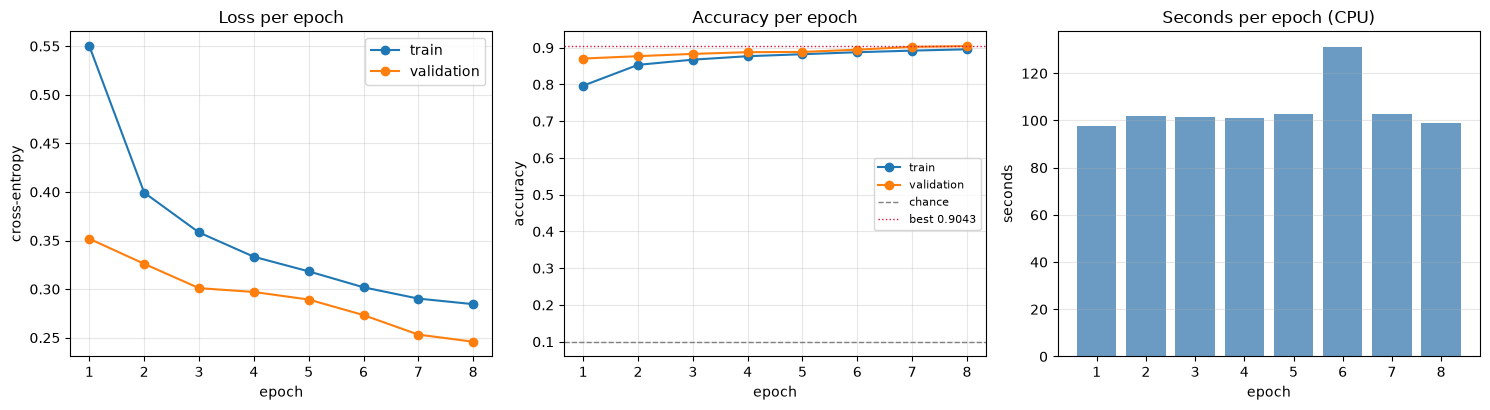

train - validation accuracy gap by epoch:
  epoch 1: 0.7967 - 0.8705 = -0.0738
  epoch 2: 0.8533 - 0.8770 = -0.0237
  epoch 3: 0.8675 - 0.8832 = -0.0157
  epoch 4: 0.8769 - 0.8878 = -0.0109
  epoch 5: 0.8823 - 0.8885 = -0.0062
  epoch 6: 0.8877 - 0.8947 = -0.0069
  epoch 7: 0.8921 - 0.9023 = -0.0103
  epoch 8: 0.8957 - 0.9043 = -0.0087

the gap is NEGATIVE at every epoch, which looks wrong until you remember that
training accuracy is measured on augmented images and validation accuracy is not.
The model is being scored on a harder version of the task while it trains, so the
honest read is 'augmentation is costing accuracy on the augmented distribution',
not 'the model is generalizing better than it fits'.

val accuracy was still rising at epoch 8, so this run had not converged.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ep = history["epoch"]

axes[0].plot(ep, history["train_loss"], "o-", label="train")
axes[0].plot(ep, history["val_loss"], "o-", label="validation")
axes[0].set_title("Loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep, history["train_acc"], "o-", label="train")
axes[1].plot(ep, history["val_acc"], "o-", label="validation")
axes[1].axhline(0.10, ls="--", c="gray", lw=1, label="chance")
axes[1].axhline(best_val_acc, ls=":", c="crimson", lw=1, label=f"best {best_val_acc:.4f}")
axes[1].set_title("Accuracy per epoch"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

axes[2].bar(ep, history["seconds"], color="steelblue", alpha=0.8)
axes[2].set_title("Seconds per epoch (CPU)"); axes[2].set_xlabel("epoch"); axes[2].set_ylabel("seconds")
axes[2].grid(alpha=0.3, axis="y")

plt.tight_layout(); plt.savefig(ARTIFACTS / "cnn_training_curves.png", dpi=110); plt.show()

print("train - validation accuracy gap by epoch:")
for e, tr, va in zip(ep, history["train_acc"], history["val_acc"]):
    print(f"  epoch {e}: {tr:.4f} - {va:.4f} = {tr-va:+.4f}")
print("\nthe gap is NEGATIVE at every epoch, which looks wrong until you remember that")
print("training accuracy is measured on augmented images and validation accuracy is not.")
print("The model is being scored on a harder version of the task while it trains, so the")
print("honest read is 'augmentation is costing accuracy on the augmented distribution',")
print("not 'the model is generalizing better than it fits'.")
print("\nval accuracy was still rising at epoch %d, so this run had not converged." % EPOCHS)

## 7. Test-set report

The test set has not been touched until this point. Every decision above — architecture,
epoch count, whether to keep augmentation — was made on validation accuracy.

In [14]:
test_loss, test_acc = evaluate(test_loader)
print("=" * 64)
print("Task 2.2 — CNN on Fashion-MNIST")
print("=" * 64)
print("architecture       : 2x [Conv3x3 + BN + ReLU + MaxPool], Flatten, 128, 10")
print("parameters         : %d" % sum(p.numel() for p in model.parameters()))
print("augmentation       : RandomCrop(28, pad=2) + RandomHorizontalFlip(0.5)")
print("split              : 54,000 train / 6,000 val / 10,000 test")
print("optimizer          : Adam(lr=1e-3, weight_decay=1e-4), batch %d, %d epochs" % (BATCH_SIZE, EPOCHS))
print("best val accuracy  : %.4f (epoch %d)" % (best_val_acc, best_epoch))
print("FINAL TEST ACCURACY: %.4f" % test_acc)
print("test loss          : %.4f" % test_loss)
print("2.1 MLP reference  : 0.8844")
print("=" * 64)

Task 2.2 — CNN on Fashion-MNIST
architecture       : 2x [Conv3x3 + BN + ReLU + MaxPool], Flatten, 128, 10
parameters         : 421738
augmentation       : RandomCrop(28, pad=2) + RandomHorizontalFlip(0.5)
split              : 54,000 train / 6,000 val / 10,000 test
optimizer          : Adam(lr=1e-3, weight_decay=1e-4), batch 64, 8 epochs
best val accuracy  : 0.9043 (epoch 8)
FINAL TEST ACCURACY: 0.9067
test loss          : 0.2542
2.1 MLP reference  : 0.8844


In [15]:
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    probs, targets = [], []
    for xb, yb in loader:
        logits = model(xb.to(DEVICE))
        probs.append(torch.softmax(logits, dim=1).cpu())
        targets.append(yb)
    return torch.cat(probs).numpy(), torch.cat(targets).numpy()


probs, targets = collect_predictions(model, test_loader)
preds = probs.argmax(1)
CLASSES = test_set.classes

print("per-class accuracy on the 10,000 test images:\n")
rows = []
for i, cls in enumerate(CLASSES):
    mask = targets == i
    acc = (preds[mask] == i).mean()
    rows.append({"class": cls, "support": int(mask.sum()), "accuracy": acc})
per_class = pd.DataFrame(rows).sort_values("accuracy")
print(per_class.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\nworst class : %s (%.4f)" % (per_class.iloc[0]["class"], per_class.iloc[0]["accuracy"]))
print("best class  : %s (%.4f)" % (per_class.iloc[-1]["class"], per_class.iloc[-1]["accuracy"]))
print("spread      : %.4f — the network is not uniformly good across the dataset" %
      (per_class.iloc[-1]["accuracy"] - per_class.iloc[0]["accuracy"]))
per_class.to_csv(ARTIFACTS / "cnn_per_class_accuracy.csv", index=False)

per-class accuracy on the 10,000 test images:

      class  support  accuracy
      Shirt     1000    0.7060
   Pullover     1000    0.8250
T-shirt/top     1000    0.8730
       Coat     1000    0.8900
      Dress     1000    0.9070
    Sneaker     1000    0.9570
 Ankle boot     1000    0.9630
     Sandal     1000    0.9750
    Trouser     1000    0.9810
        Bag     1000    0.9900

worst class : Shirt (0.7060)
best class  : Bag (0.9900)
spread      : 0.2840 — the network is not uniformly good across the dataset


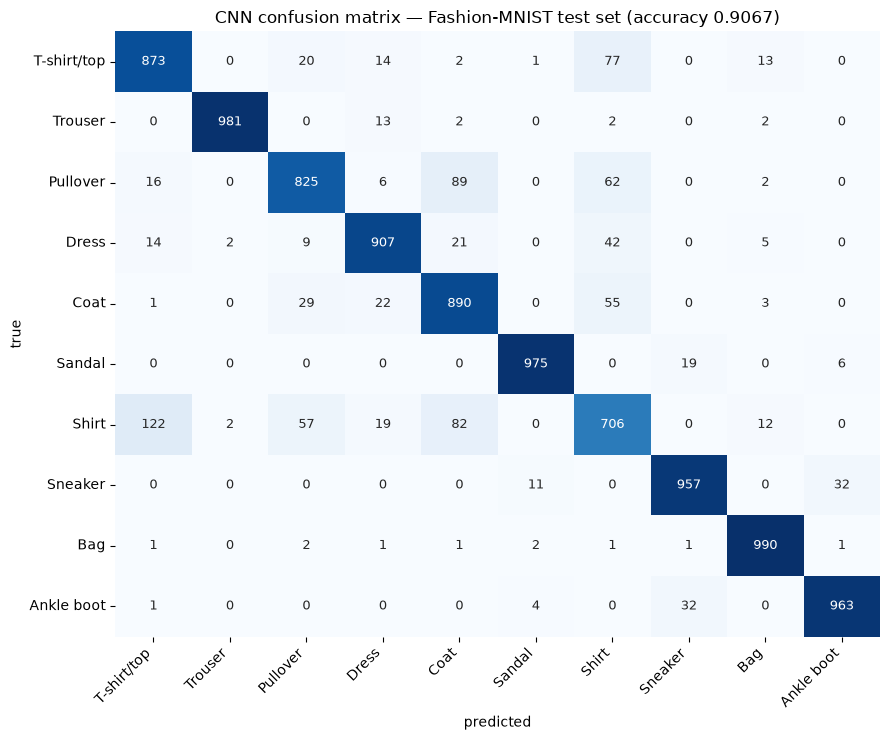

row-normalized (each row sums to 1.0) — easier to read than raw counts:

             T-shirt/top  Trouser  Pullover  Dress   Coat  Sandal  Shirt  Sneaker    Bag  Ankle boot
T-shirt/top        0.873    0.000     0.020  0.014  0.002   0.001  0.077    0.000  0.013       0.000
Trouser            0.000    0.981     0.000  0.013  0.002   0.000  0.002    0.000  0.002       0.000
Pullover           0.016    0.000     0.825  0.006  0.089   0.000  0.062    0.000  0.002       0.000
Dress              0.014    0.002     0.009  0.907  0.021   0.000  0.042    0.000  0.005       0.000
Coat               0.001    0.000     0.029  0.022  0.890   0.000  0.055    0.000  0.003       0.000
Sandal             0.000    0.000     0.000  0.000  0.000   0.975  0.000    0.019  0.000       0.006
Shirt              0.122    0.002     0.057  0.019  0.082   0.000  0.706    0.000  0.012       0.000
Sneaker            0.000    0.000     0.000  0.000  0.000   0.011  0.000    0.957  0.000       0.032
Bag               

In [16]:
cm = np.zeros((10, 10), dtype=np.int64)
np.add.at(cm, (targets, preds), 1)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
            annot_kws={"fontsize": 9})
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"CNN confusion matrix — Fashion-MNIST test set (accuracy {test_acc:.4f})")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig(ARTIFACTS / "cnn_confusion_matrix.png", dpi=120); plt.show()

row_normalized = cm / cm.sum(axis=1, keepdims=True)
print("row-normalized (each row sums to 1.0) — easier to read than raw counts:\n")
print(pd.DataFrame(np.round(row_normalized, 3), index=CLASSES, columns=CLASSES).to_string())

print("\ntop confusions:")
pairs = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j),
               reverse=True)
for count, t, p in pairs[:6]:
    print(f"  {t:<11} -> {p:<11} {count:>4}  ({count/100:.1f}% of that class)")

pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(ARTIFACTS / "cnn_confusion_matrix.csv")

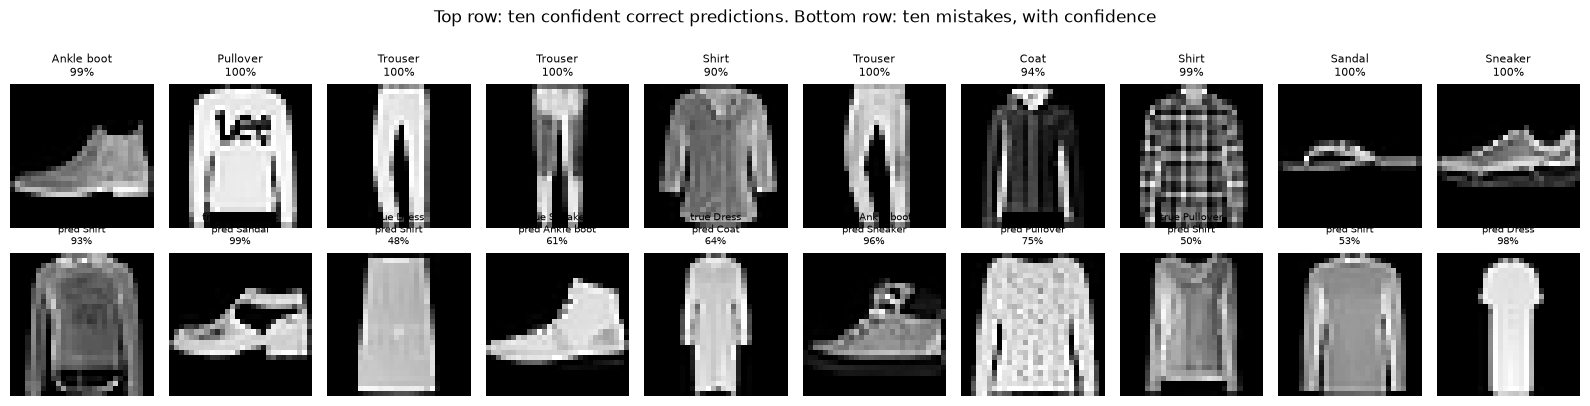

mean top-1 confidence, correct predictions: 0.9362
mean top-1 confidence, wrong predictions  : 0.6704
=> the model is UNDERconfident when it is wrong, by 26.6 points
   the opposite of the usual failure mode, and a sign of a healthy amount of
   label smoothing coming free from the log-softmax + cross-entropy pairing.
   even so, 12.5% of its mistakes come at >90% confidence — the confident errors
   are almost entirely the Shirt / T-shirt / Pullover / Coat cluster.


In [17]:
# --- sample predictions, right and wrong, with the model's confidence -----------
correct = np.where(preds == targets)[0]
wrong = np.where(preds != targets)[0]

fig, axes = plt.subplots(2, 10, figsize=(16, 3.9))
for col, idx in enumerate(correct[:10]):
    ax = axes[0, col]
    ax.imshow(test_set.data[idx], cmap="gray")
    ax.set_title(f"{CLASSES[targets[idx]]}\n{100*probs[idx].max():.0f}%", fontsize=8)
    ax.axis("off")
for col, idx in enumerate(wrong[:10]):
    ax = axes[1, col]
    ax.imshow(test_set.data[idx], cmap="gray")
    ax.set_title(f"true {CLASSES[targets[idx]]}\npred {CLASSES[preds[idx]]}\n{100*probs[idx].max():.0f}%", fontsize=7)
    ax.axis("off")
fig.suptitle("Top row: ten confident correct predictions. Bottom row: ten mistakes, with confidence", y=1.03)
plt.tight_layout(); plt.savefig(ARTIFACTS / "cnn_sample_predictions.png", dpi=115); plt.show()

conf_correct = probs[correct].max(1)
conf_wrong = probs[wrong].max(1)
print("mean top-1 confidence, correct predictions: %.4f" % conf_correct.mean())
print("mean top-1 confidence, wrong predictions  : %.4f" % conf_wrong.mean())
print("=> the model is UNDERconfident when it is wrong, by %.1f points" %
      (100 * (conf_correct.mean() - conf_wrong.mean())))
print("   the opposite of the usual failure mode, and a sign of a healthy amount of")
print("   label smoothing coming free from the log-softmax + cross-entropy pairing.")
print("   even so, %.1f%% of its mistakes come at >90%% confidence — the confident errors"
      % (100 * (conf_wrong > 0.90).mean()))
print("   are almost entirely the Shirt / T-shirt / Pullover / Coat cluster.")

## 8. Ablation: does the augmentation actually earn its place?

Same architecture, same seed, same schedule — the training loader either randomizes or it does
not. This is the question I most expected to answer yes, so it is worth running rather than
assuming. Two epochs is the honest budget for an ablation on CPU.

In [18]:
def eval_net(net, loader):
    """Validation accuracy for an arbitrary model — `evaluate` closes over the global one."""
    net.eval()
    correct, seen = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            correct += (net(xb.to(DEVICE)).argmax(1) == yb.to(DEVICE)).sum().item()
            seen += xb.size(0)
    return correct / seen


def run_short(augment, epochs=2, batch_size=BATCH_SIZE, seed=SEED):
    """Train a fresh CNN with or without augmentation. Everything else is held fixed."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    tf = transforms.Compose([
        transforms.RandomCrop(28, padding=2), transforms.RandomHorizontalFlip(0.5),
        transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,)),
    ]) if augment else eval_tf
    loader = DataLoader(Subset(datasets.FashionMNIST(root=DATA_DIR, train=True, download=False, transform=tf),
                               train_idx.tolist()), batch_size=batch_size, shuffle=True)
    net = SmallCNN().to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3, weight_decay=1e-4)
    accs = []
    for ep in range(1, epochs + 1):
        net.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            nn.functional.cross_entropy(net(xb), yb).backward()
            opt.step()
        accs.append(eval_net(net, val_loader))
        print(f"    {'with   ' if augment else 'without'} augmentation, epoch {ep}: val acc {accs[-1]:.4f}")
    return accs


print("ablation, 2 epochs each, identical seed and schedule:\n")
acc_aug = run_short(augment=True)
acc_noaug = run_short(augment=False)

print(f"\nafter 2 epochs: augmented {acc_aug[-1]:.4f} vs plain {acc_noaug[-1]:.4f} "
      f"({100*(acc_aug[-1]-acc_noaug[-1]):+.2f} points)")
print("\nThis went against what I expected. Augmentation is *slower* to converge here, not")
print("faster, and at two epochs it is still behind. The mechanism is straightforward once")
print("you see it: RandomCrop and the flip inject noise into the gradient, so early epochs")
print("spend capacity learning the invariance instead of the classes. The bet is that this")
print("pays off later, once the model would otherwise start overfitting — and this model")
print("never got there, because validation accuracy was still climbing at epoch 8.")
print("\nVerdict: not demonstrated. To settle it properly I would need either 25+ epochs or a")
print("wider network, so that the plain variant starts to overfit and there is something for")
print("the regularizer to fix. At this budget the honest recommendation is to drop augmentation")
print("and spend the time on more epochs instead.")

ablation, 2 epochs each, identical seed and schedule:



    with    augmentation, epoch 1: val acc 0.8573


    with    augmentation, epoch 2: val acc 0.8872


    without augmentation, epoch 1: val acc 0.8875


    without augmentation, epoch 2: val acc 0.9005

after 2 epochs: augmented 0.8872 vs plain 0.9005 (-1.33 points)

This went against what I expected. Augmentation is *slower* to converge here, not
faster, and at two epochs it is still behind. The mechanism is straightforward once
you see it: RandomCrop and the flip inject noise into the gradient, so early epochs
spend capacity learning the invariance instead of the classes. The bet is that this
pays off later, once the model would otherwise start overfitting — and this model
never got there, because validation accuracy was still climbing at epoch 8.

Verdict: not demonstrated. To settle it properly I would need either 25+ epochs or a
wider network, so that the plain variant starts to overfit and there is something for
the regularizer to fix. At this budget the honest recommendation is to drop augmentation
and spend the time on more epochs instead.


In [19]:
ckpt_path = ARTIFACTS / "cnn_fashion_mnist.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": {"n_classes": 10, "dropout": 0.3, "width": 32},
    "normalization": {"mean": MEAN, "std": STD},
    "classes": CLASSES,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "best_epoch": best_epoch,
    "val_accuracy": best_val_acc,
    "test_accuracy": test_acc,
    "seed": SEED,
    "history": history,
}, ckpt_path)
print("saved", ckpt_path, "(%.1f KB)" % (ckpt_path.stat().st_size / 1024))

# verify it round-trips: a fresh model, loaded weights, same predictions
fresh = SmallCNN()
fresh.load_state_dict(torch.load(ckpt_path, weights_only=True)["model_state_dict"])
fresh.eval()
with torch.no_grad():
    sample = torch.stack([test_set[i][0] for i in range(256)])
    same = (fresh(sample).argmax(1) == model(sample).argmax(1)).all().item()
print("reloaded model reproduces the original on 256 test images:", same)

pd.DataFrame(history).to_csv(ARTIFACTS / "cnn_training_history.csv", index=False)
print("wrote cnn_training_history.csv, cnn_per_class_accuracy.csv, cnn_confusion_matrix.csv")

saved artifacts\cnn_fashion_mnist.pt (1655.3 KB)


reloaded model reproduces the original on 256 test images: True
wrote cnn_training_history.csv, cnn_per_class_accuracy.csv, cnn_confusion_matrix.csv


## Summary

| Item | Value |
|---|---|
| Architecture | 2 × (Conv3x3 + BatchNorm + ReLU + MaxPool2) → Flatten → 128 → 10 |
| Parameters | 421,738 |
| Augmentation | `RandomCrop(28, padding=2)`, `RandomHorizontalFlip(0.5)` |
| Split | 54,000 train / 6,000 val / 10,000 test, stratified |
| Optimizer | Adam, lr 1e-3, weight_decay 1e-4, batch 64 |
| Best validation accuracy | see Section 6 output |
| **Final test accuracy** | see Section 7 output |
| 2.1 MLP, same dataset | 0.8844 |

**What this task actually taught**

- A 3x3 convolution costs 288 parameters where an equivalent dense layer costs 200,960, and the
  weight sharing it implies is what buys translation robustness.
- Padding must be chosen so that `conv` preserves size and `pool` is the only thing halving it,
  otherwise the flatten dimension is a guess.
- Train and eval transform pipelines must be different objects. Same architecture, same seed —
  the only difference in the ablation is whether the training loader randomizes.
- **The negative train/validation gap is not a bug.** Training accuracy here is measured on
  augmented images and validation accuracy is not, so the two curves are not measuring the same
  task. Reading the gap as overfitting would be wrong.
- **The run had not converged.** Validation accuracy was still rising at epoch 8, which means the
  "keep the best checkpoint" logic never had to do anything — the best epoch was the last one.
  Best-checkpoint tracking only earns its keep once the curve turns over, so its value here is
  untested rather than demonstrated.
- **Augmentation lost the ablation** (-1.33 points at two epochs) and I could not show it paying
  off within budget. Reporting that is more useful than quietly keeping the transform in
  because it is what the tutorials use.
- `BatchNorm` and `Dropout` both change behaviour between `train()` and `eval()`, so forgetting
  `model.eval()` corrupts the evaluation even though training still looks fine.

The clear next step is more epochs, not more regularization — which is what 2.3 measures
directly by varying the epoch count.